In [1]:
#Import Statements
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
)

RANDOM_STATE = 42

In [2]:
#Loading the dataset
DATA_PATH = Path("../data/raw/AAPL_daily_raw.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("data/raw/AAPL_daily_raw.csv")

df = pd.read_csv(DATA_PATH, index_col=0)

# Preserve the trading dates as displayed in the CSV.
df.index = pd.to_datetime(
    df.index.astype(str).str.slice(0, 19),
    errors="raise"
)

df = df.sort_index()
df.index.name = "Date"

print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print(df.head())

Shape: (2766, 9)
Date range: 2015-01-02 to 2025-12-31
                 Open       High        Low      Close  Adj Close     Volume  \
Date                                                                           
2015-01-02  27.847500  27.860001  26.837500  27.332500  24.171755  212818400   
2015-01-05  27.072500  27.162500  26.352501  26.562500  23.490799  257142000   
2015-01-06  26.635000  26.857500  26.157499  26.565001  23.493013  263188400   
2015-01-07  26.799999  27.049999  26.674999  26.937500  23.822430  160423600   
2015-01-08  27.307501  28.037500  27.174999  27.972500  24.737757  237458000   

            Dividends  Stock Splits  daily_return  
Date                                               
2015-01-02        0.0           0.0           NaN  
2015-01-05        0.0           0.0     -0.028172  
2015-01-06        0.0           0.0      0.000094  
2015-01-07        0.0           0.0      0.014022  
2015-01-08        0.0           0.0      0.038423  


In [3]:
#Builiding Features and Traget
FEATURES = [
    "return_1d",
    "return_5d",
    "return_10d",
    "price_to_sma20",
    "price_to_sma50",
    "volatility_20d",
    "momentum_10d",
    "relative_volume",
]

df["return_1d"] = df["Adj Close"].pct_change(1)
df["return_5d"] = df["Adj Close"].pct_change(5)
df["return_10d"] = df["Adj Close"].pct_change(10)

df["sma20"] = df["Adj Close"].rolling(20).mean()
df["sma50"] = df["Adj Close"].rolling(50).mean()

df["price_to_sma20"] = df["Adj Close"] / df["sma20"] - 1
df["price_to_sma50"] = df["Adj Close"] / df["sma50"] - 1

df["volatility_20d"] = df["return_1d"].rolling(20).std()
df["momentum_10d"] = df["Adj Close"].pct_change(10)

df["relative_volume"] = (
    df["Volume"] / df["Volume"].rolling(20).mean()
)

df["future_return_1d"] = (
    df["Adj Close"].shift(-1) / df["Adj Close"] - 1
)
df["target_up"] = (df["future_return_1d"] > 0).astype(int)

model_df = df[
    FEATURES + ["future_return_1d", "target_up"]
].dropna().copy()

X = model_df[FEATURES]
y = model_df["target_up"]

print("Rows:", len(model_df))
print(y.value_counts().rename(index={0: "DOWN", 1: "UP"}))

Rows: 2716
target_up
UP      1438
DOWN    1278
Name: count, dtype: int64


In [4]:
#Chronologically Splitting the data
n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_idx = np.arange(0, train_end - 1)
val_idx = np.arange(train_end, val_end - 1)
test_idx = np.arange(val_end, n)

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

for name, X_part in [
    ("Train", X_train),
    ("Validation", X_val),
    ("Test", X_test),
]:
    print(
        f"{name}: {X_part.index.min().date()} to "
        f"{X_part.index.max().date()} | rows={len(X_part)}"
    )

assert X_train.index.max() < X_val.index.min()
assert X_val.index.max() < X_test.index.min()

Train: 2015-03-16 to 2022-09-28 | rows=1900
Validation: 2022-09-30 to 2024-05-13 | rows=406
Test: 2024-05-15 to 2025-12-30 | rows=408


In [5]:
toy_rows = np.array(["A", "B", "C", "D", "E"])

rng = np.random.default_rng(RANDOM_STATE)

sampled_rows = rng.choice(
    toy_rows,
    size=len(toy_rows),
    replace=True
)

print("Original rows:", toy_rows)
print("Bootstrap sample:", sampled_rows)
print("Unique sampled rows:", np.unique(sampled_rows))
print("Rows left out:", np.setdiff1d(toy_rows, sampled_rows))

Original rows: ['A' 'B' 'C' 'D' 'E']
Bootstrap sample: ['A' 'D' 'D' 'C' 'C']
Unique sampled rows: ['A' 'C' 'D']
Rows left out: ['B' 'E']


In [7]:
#Training a forest with Out of bag evalation enabled
rf_oob = RandomForestClassifier(
    n_estimators=200,
    max_features="sqrt",
    max_depth=None,
    min_samples_leaf=20,
    min_samples_split=40,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

rf_oob.fit(X_train, y_train)

print("OOB accuracy:", round(rf_oob.oob_score_, 4))
print(
    "Validation accuracy:",
    round(accuracy_score(y_val, rf_oob.predict(X_val)), 4)
)
print(
    "Validation balanced accuracy:",
    round(balanced_accuracy_score(y_val, rf_oob.predict(X_val)), 4)
)

OOB accuracy: 0.5063
Validation accuracy: 0.4828
Validation balanced accuracy: 0.4772


In [8]:
#Inspect the OOB Predictions
oob_probabilities = pd.DataFrame(
    rf_oob.oob_decision_function_,
    index=X_train.index,
    columns=[f"class_{c}" for c in rf_oob.classes_]
)

print(oob_probabilities.head())
print(
    "Training rows with complete OOB probabilities:",
    oob_probabilities.notna().all(axis=1).sum(),
    "of",
    len(oob_probabilities)
)

             class_0   class_1
Date                          
2015-03-16  0.480275  0.519725
2015-03-17  0.536269  0.463731
2015-03-18  0.413027  0.586973
2015-03-19  0.464311  0.535689
2015-03-20  0.407722  0.592278
Training rows with complete OOB probabilities: 1900 of 1900


In [9]:
#Tune the random forest using validation data
configs = []

for n_estimators in [100, 200]:
    for max_features in ["sqrt", 0.75]:
        for max_depth in [5, 10, None]:
            for min_samples_leaf in [10, 30]:
                configs.append({
                    "n_estimators": n_estimators,
                    "max_features": max_features,
                    "max_depth": max_depth,
                    "min_samples_leaf": min_samples_leaf,
                })

print("Number of configurations:", len(configs))

Number of configurations: 24


In [10]:
#Train and score each configuration
results = []

for i, params in enumerate(configs, start=1):
    model = RandomForestClassifier(
        **params,
        min_samples_split=40,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    results.append({
        **params,
        "train_balanced_accuracy": balanced_accuracy_score(
            y_train, train_pred
        ),
        "val_balanced_accuracy": balanced_accuracy_score(
            y_val, val_pred
        ),
        "val_macro_f1": f1_score(
            y_val, val_pred, average="macro", zero_division=0
        ),
        "oob_accuracy": model.oob_score_,
    })

    if i % 4 == 0:
        print(f"Completed {i}/{len(configs)} configurations")

results_df = pd.DataFrame(results)

results_df["train_val_gap"] = (
    results_df["train_balanced_accuracy"]
    - results_df["val_balanced_accuracy"]
)

results_df = results_df.sort_values(
    ["val_balanced_accuracy", "val_macro_f1"],
    ascending=False
).reset_index(drop=True)

results_df.round(4).head(10)

Completed 4/24 configurations
Completed 8/24 configurations
Completed 12/24 configurations
Completed 16/24 configurations
Completed 20/24 configurations
Completed 24/24 configurations


,n_estimators,max_features,max_depth,min_samples_leaf,train_balanced_accuracy,val_balanced_accuracy,val_macro_f1,oob_accuracy,train_val_gap
0,100,sqrt,5.0,30,0.6006,0.5265,0.4840,0.5121,0.0741
1,200,sqrt,5.0,30,0.6018,0.5219,0.4821,0.5053,0.0798
2,100,0.75,5.0,10,0.6144,0.5153,0.4816,0.5295,0.0991
3,200,0.75,5.0,10,0.6104,0.5148,0.4766,0.5268,0.0956
4,200,0.75,5.0,30,0.6046,0.5131,0.4813,0.5247,0.0915
5,100,sqrt,10.0,30,0.6789,0.5128,0.4955,0.4953,0.1662
6,100,sqrt,5.0,10,0.6011,0.5126,0.4764,0.5016,0.0885
7,200,sqrt,NaN,10,0.8094,0.5122,0.5041,0.5068,0.2971
8,200,sqrt,5.0,10,0.6083,0.5121,0.4712,0.5132,0.0962
9,100,0.75,10.0,30,0.6941,0.5109,0.4967,0.5032,0.1832


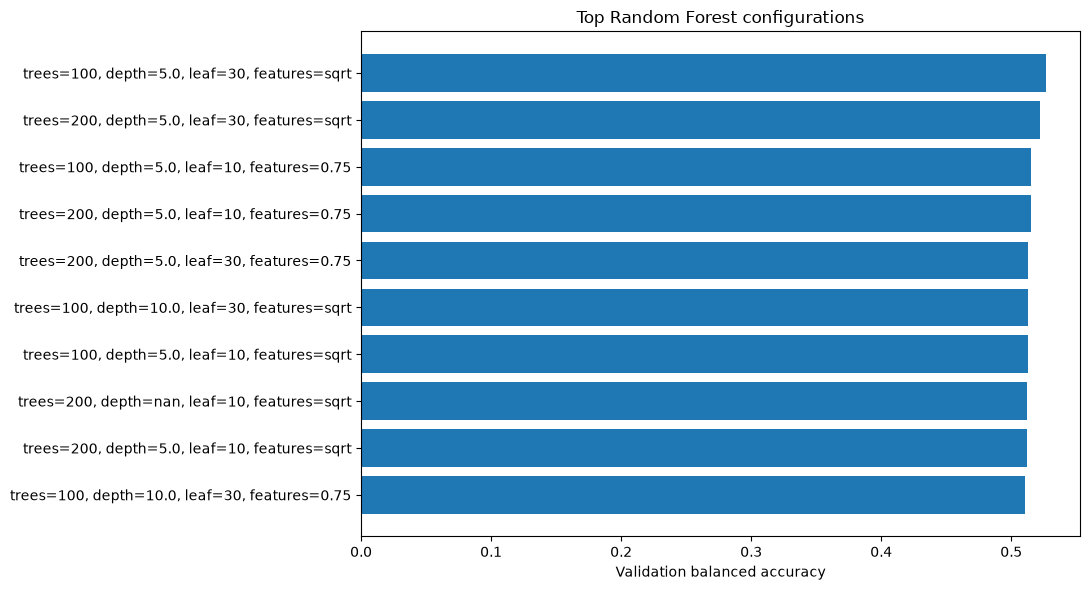

In [11]:
#Visualize the top configurations
top_results = results_df.head(10).copy()

labels = [
    f"trees={r.n_estimators}, depth={r.max_depth}, "
    f"leaf={r.min_samples_leaf}, features={r.max_features}"
    for r in top_results.itertuples()
]

plt.figure(figsize=(11, 6))
plt.barh(
    labels[::-1],
    top_results["val_balanced_accuracy"].to_numpy()[::-1]
)
plt.xlabel("Validation balanced accuracy")
plt.title("Top Random Forest configurations")
plt.tight_layout()
plt.show()

In [12]:
#Selecting the model and evaluating test set
best_params = results_df.iloc[0][
    ["n_estimators", "max_features", "max_depth", "min_samples_leaf"]
].to_dict()

best_params["n_estimators"] = int(best_params["n_estimators"])
best_params["min_samples_leaf"] = int(best_params["min_samples_leaf"])

if pd.isna(best_params["max_depth"]):
    best_params["max_depth"] = None
else:
    best_params["max_depth"] = int(best_params["max_depth"])

print("Selected parameters:", best_params)

best_rf = RandomForestClassifier(
    **best_params,
    min_samples_split=40,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

best_rf.fit(X_train, y_train)

Selected parameters: {'n_estimators': 100, 'max_features': 'sqrt', 'max_depth': 5, 'min_samples_leaf': 30}


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",40
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",30
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.B

In [13]:
#Compare with majority baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

comparison_rows = []

for name, model in [
    ("Majority baseline", baseline),
    ("Tuned Random Forest", best_rf),
]:
    predictions = model.predict(X_test)

    comparison_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "macro_f1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    })

test_comparison = pd.DataFrame(comparison_rows).set_index("model")
test_comparison.round(4)

,accuracy,balanced_accuracy,macro_f1
model,,,
Majority baseline,0.5662,0.500,0.3615
Tuned Random Forest,0.5392,0.496,0.4555


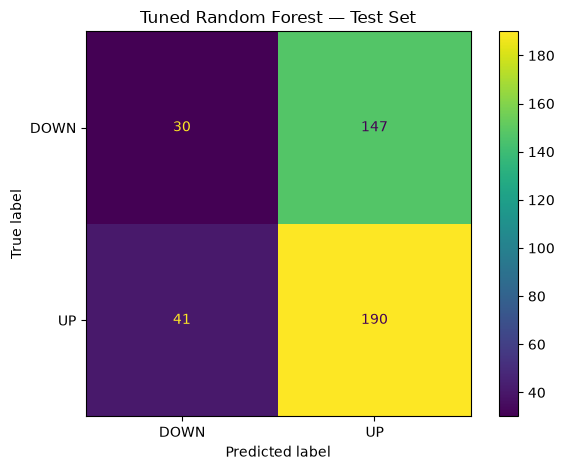

              precision    recall  f1-score   support

        DOWN       0.42      0.17      0.24       177
          UP       0.56      0.82      0.67       231

    accuracy                           0.54       408
   macro avg       0.49      0.50      0.46       408
weighted avg       0.50      0.54      0.48       408



In [15]:
test_predictions = best_rf.predict(X_test)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test, test_predictions, labels=[0, 1]
    ),
    display_labels=["DOWN", "UP"]
).plot()

plt.title("Tuned Random Forest — Test Set")
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["DOWN", "UP"],
        zero_division=0
    )
)